# LD-MGF: Empirical Validation of Local Density – Multi-Granularity Fusion Index
## Unsupervised Clustering Evaluation Across Clinical & Epidemiological Benchmarks

**Author / Researcher:** Research Team  
**Environment:** Lightweight CPU, Python 3.11, Scikit-Learn, SciPy  
**Target Datasets:**
1. **UCI Heart Disease** (Cleveland Clinic, $N=303$, $D=13$ clinical features)
2. **NHANES 2017–2018** (CDC Epidemiological Cohort, $N=3,000$ adult records, $D=12$ biomarkers)
3. **Diabetes 130-US Hospitals** (Clinical Encounter Cohort, $N=3,000$ patients, $D=43$ clinical attributes)

---

### Research Objectives & Execution Plan
- **Data Integrity:** Load and preprocess three real-world medical datasets. Impute missing values, encode categoricals, standardize continuous features, and strictly isolate diagnostic/outcome labels from clustering feature matrices.
- **Clustering Paradigms:** Implement and compare 5 distinct clustering algorithms:
  1. *K-Means* (Centroid-based)
  2. *Agglomerative Clustering* (Hierarchical Ward linkage)
  3. *DBSCAN* (Density-based with noise isolation)
  4. *OPTICS* (Ordering points to identify density cluster structure)
  5. *Gaussian Mixture Models (GMM)* (Probabilistic expectation-maximization)
- **Validation Framework:** Compute standard and advanced Cluster Validity Indices (CVIs):
  - Silhouette Score (SC)
  - Davies–Bouldin Index (DBI)
  - Calinski–Harabasz Index (CHI)
  - Dunn Index (DI)
  - Density-Based Clustering Validation (DBCV)
- **Proposed Index (LD-MGF):** Formalize the mathematical foundations, density assumptions, multi-granularity separation components, and implement the **Local Density – Multi-Granularity Fusion Index**.
- **Visual Analytics:** Present 2D PCA cluster projections, CVI comparison charts, runtime efficiency profiles, and export consolidated metrics to CSV.


In [1]:
# Core Scientific Libraries
import os
import sys
import time
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# SciPy and Scikit-Learn
from scipy.spatial.distance import cdist, pdist, squareform
from scipy.sparse.csgraph import minimum_spanning_tree
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, OPTICS
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.neighbors import NearestNeighbors

# Plotting Configuration
%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
sns.set_style('whitegrid')

# Ensure directories exist
os.makedirs('../results/metrics', exist_ok=True) if os.path.exists('../results') else os.makedirs('results/metrics', exist_ok=True)
os.makedirs('../results/figures', exist_ok=True) if os.path.exists('../results') else os.makedirs('results/figures', exist_ok=True)

def find_data_dir(dataset_name):
    """Finds dataset directory relative to root or notebooks/ folder."""
    candidates = [
        os.path.join('..', 'data', 'raw', dataset_name),
        os.path.join('data', 'raw', dataset_name),
        os.path.join('..', '..', 'data', 'raw', dataset_name)
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    return os.path.join('data', 'raw', dataset_name)

def get_results_dir(subfolder):
    """Finds results output directory relative to root or notebooks/ folder."""
    candidates = [
        os.path.join('..', 'results', subfolder),
        os.path.join('results', subfolder)
    ]
    for p in candidates:
        if os.path.exists(os.path.dirname(p)):
            os.makedirs(p, exist_ok=True)
            return p
    os.makedirs(os.path.join('results', subfolder), exist_ok=True)
    return os.path.join('results', subfolder)

print("Environment initialized successfully. Random state seed: 42.")


Environment initialized successfully. Random state seed: 42.


## 1. Dataset Loading, Cleaning & Preprocessing
To adhere strictly to unsupervised clustering research standards:
- **No Ground-Truth Leakage:** Disease outcome labels (`target` in Heart Disease, `readmitted` in Diabetes 130, and high-risk biomarker thresholds in NHANES) are extracted and preserved exclusively for post-hoc validation. They are strictly excluded from the clustering feature space $X$.
- **Preservation of Raw Files:** Raw data in `data/raw/` remains untouched.
- **Missing Value Imputation:** Handled via clinical mode/median strategies.
- **Categorical Encoding:** One-hot encoding for multi-class nominal variables and ordinal encoding for graded scales.
- **Feature Scaling:** All features are standardized via zero-mean, unit-variance ($z$-score) scaling:
  $$z = \frac{x - \mu}{\sigma}$$


In [2]:
def load_heart_disease(base_dir=None):
    """Loads and preprocesses UCI Heart Disease dataset (Cleveland)."""
    if base_dir is None:
        base_dir = find_data_dir('heart_disease')
    filepath = os.path.join(base_dir, 'processed.cleveland.data')
    cols = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 
            'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']
    df = pd.read_csv(filepath, header=None, names=cols, na_values='?')
    
    # Impute missing values with mode (ca has 4 missing, thal has 2 missing)
    df['ca'] = df['ca'].fillna(df['ca'].mode()[0])
    df['thal'] = df['thal'].fillna(df['thal'].mode()[0])
    
    # Isolate ground truth label (binary: 0 = healthy, 1 = heart disease present)
    y = (df['target'].values > 0).astype(int)
    features_df = df.drop(columns=['target']).copy()
    
    # One-hot encode multi-category nominal features: cp (1-4), restecg (0-2), slope (1-3), thal (3,6,7)
    cat_cols = ['cp', 'restecg', 'slope', 'thal']
    encoded_cat = pd.get_dummies(features_df[cat_cols].astype(str), drop_first=True, dtype=float)
    
    num_cols = ['age', 'sex', 'trestbps', 'chol', 'fbs', 'thalach', 'exang', 'oldpeak', 'ca']
    clean_df = pd.concat([features_df[num_cols], encoded_cat], axis=1)
    
    feature_names = clean_df.columns.tolist()
    X = StandardScaler().fit_transform(clean_df)
    return X, y, feature_names, clean_df


def load_nhanes(base_dir=None, sample_size=3000, random_state=42):
    """Loads and merges NHANES 2017-2018 SAS XPT exam and laboratory datasets."""
    if base_dir is None:
        base_dir = find_data_dir('nhanes_2017_2018')
    demo = pd.read_sas(os.path.join(base_dir, 'DEMO_J.xpt'), format='xport')[['SEQN', 'RIAGENDR', 'RIDAGEYR']]
    bmx = pd.read_sas(os.path.join(base_dir, 'BMX_J.xpt'), format='xport')[['SEQN', 'BMXWT', 'BMXHT', 'BMXBMI', 'BMXWAIST']]
    bpx = pd.read_sas(os.path.join(base_dir, 'BPX_J.xpt'), format='xport')[['SEQN', 'BPXSY1', 'BPXDI1', 'BPXPLS']]
    ghb = pd.read_sas(os.path.join(base_dir, 'GHB_J.xpt'), format='xport')[['SEQN', 'LBXGH']]
    hdl = pd.read_sas(os.path.join(base_dir, 'HDL_J.xpt'), format='xport')[['SEQN', 'LBDHDD']]
    tchol = pd.read_sas(os.path.join(base_dir, 'TCHOL_J.xpt'), format='xport')[['SEQN', 'LBXTC']]
    
    merged = demo.merge(bmx, on='SEQN', how='inner')
    merged = merged.merge(bpx, on='SEQN', how='inner')
    merged = merged.merge(ghb, on='SEQN', how='inner')
    merged = merged.merge(hdl, on='SEQN', how='inner')
    merged = merged.merge(tchol, on='SEQN', how='inner')
    
    adults = merged[merged['RIDAGEYR'] >= 18].copy()
    adults = adults.drop(columns=['SEQN'])
    adults = adults.fillna(adults.median())
    
    rename_dict = {
        'RIDAGEYR': 'Age', 'RIAGENDR': 'Gender_Female', 'BMXWT': 'Weight_kg',
        'BMXHT': 'Height_cm', 'BMXBMI': 'BMI', 'BMXWAIST': 'Waist_cm',
        'BPXSY1': 'Systolic_BP', 'BPXDI1': 'Diastolic_BP', 'BPXPLS': 'Pulse',
        'LBXGH': 'Glycohemoglobin_HbA1c', 'LBDHDD': 'HDL_Cholesterol', 'LBXTC': 'Total_Cholesterol'
    }
    adults = adults.rename(columns=rename_dict)
    adults['Gender_Female'] = (adults['Gender_Female'] == 2).astype(float)
    
    # External cardiometabolic risk proxy (HbA1c >= 6.5 or BMI >= 30.0)
    y_full = ((adults['Glycohemoglobin_HbA1c'] >= 6.5) | (adults['BMI'] >= 30.0)).astype(int).values
    
    if sample_size is not None and len(adults) > sample_size:
        rng = np.random.RandomState(random_state)
        idx = rng.choice(len(adults), size=sample_size, replace=False)
        adults = adults.iloc[idx].reset_index(drop=True)
        y = y_full[idx]
    else:
        y = y_full
        
    feature_names = adults.columns.tolist()
    X = StandardScaler().fit_transform(adults)
    return X, y, feature_names, adults


def load_diabetes_130(base_dir=None, sample_size=3000, random_state=42):
    """Loads and preprocesses Diabetes 130-US Hospitals dataset."""
    if base_dir is None:
        base_dir = find_data_dir('diabetes_130')
    filepath = os.path.join(base_dir, 'diabetic_data.csv')
    df = pd.read_csv(filepath, na_values='?', low_memory=False)
    
    # Drop identifiers and sparse attributes (>40% missing)
    drop_cols = ['encounter_id', 'patient_nbr', 'weight', 'payer_code', 'medical_specialty',
                 'diag_1', 'diag_2', 'diag_3']
    clean_df = df.drop(columns=drop_cols).copy()
    
    # Target label: 30-day readmission status (<30 vs NO / >30)
    y_full = (clean_df['readmitted'] == '<30').astype(int).values
    clean_df = clean_df.drop(columns=['readmitted'])
    
    # Age range mapping to midpoint
    age_map = {'[0-10)': 5, '[10-20)': 15, '[20-30)': 25, '[30-40)': 35, '[40-50)': 45,
               '[50-60)': 55, '[60-70)': 65, '[70-80)': 75, '[80-90)': 85, '[90-100)': 95}
    clean_df['age'] = clean_df['age'].map(age_map).fillna(55.0)
    clean_df['gender'] = clean_df['gender'].map({'Male': 1, 'Female': 0}).fillna(0)
    
    med_cols = ['metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride',
                'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone',
                'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide',
                'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin',
                'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone']
    med_map = {'No': 0, 'Steady': 1, 'Up': 2, 'Down': 2}
    for m in med_cols:
        if m in clean_df.columns:
            clean_df[m] = clean_df[m].map(med_map).fillna(0).astype(float)
            
    clean_df['change'] = (clean_df['change'] == 'Ch').astype(float)
    clean_df['diabetesMed'] = (clean_df['diabetesMed'] == 'Yes').astype(float)
    
    clean_df['race'] = clean_df['race'].fillna('Missing')
    race_dummies = pd.get_dummies(clean_df['race'], prefix='race', drop_first=True, dtype=float)
    clean_df = clean_df.drop(columns=['race'])
    clean_df = pd.concat([clean_df, race_dummies], axis=1)
    
    numeric_cols = [c for c in clean_df.columns if clean_df[c].dtype in [np.float64, np.int64, float, int]]
    clean_df = clean_df[numeric_cols].fillna(clean_df[numeric_cols].median())
    
    if sample_size is not None and len(clean_df) > sample_size:
        rng = np.random.RandomState(random_state)
        idx = rng.choice(len(clean_df), size=sample_size, replace=False)
        clean_df = clean_df.iloc[idx].reset_index(drop=True)
        y = y_full[idx]
    else:
        y = y_full
        
    feature_names = clean_df.columns.tolist()
    X = StandardScaler().fit_transform(clean_df)
    return X, y, feature_names, clean_df
        
    feature_names = clean_df.columns.tolist()
    X = StandardScaler().fit_transform(clean_df)
    return X, y, feature_names, clean_df

print("Loading and preprocessing datasets...")
X_heart, y_heart, feat_heart, df_raw_heart = load_heart_disease()
X_nhanes, y_nhanes, feat_nhanes, df_raw_nhanes = load_nhanes(sample_size=3000)
X_diab, y_diab, feat_diab, df_raw_diab = load_diabetes_130(sample_size=3000)

data_summary = pd.DataFrame([
    {'Dataset': 'UCI Heart Disease', 'Samples (N)': X_heart.shape[0], 'Features (D)': X_heart.shape[1], 'Preserved Target': 'Diagnosis (0=No, 1=Yes)', 'Class Prevalence (%)': f'{y_heart.mean()*100:.1f}%'},
    {'Dataset': 'NHANES 2017-2018', 'Samples (N)': X_nhanes.shape[0], 'Features (D)': X_nhanes.shape[1], 'Preserved Target': 'Cardiometabolic Risk', 'Class Prevalence (%)': f'{y_nhanes.mean()*100:.1f}%'},
    {'Dataset': 'Diabetes 130 Hospitals', 'Samples (N)': X_diab.shape[0], 'Features (D)': X_diab.shape[1], 'Preserved Target': 'Readmission (<30 days)', 'Class Prevalence (%)': f'{y_diab.mean()*100:.1f}%'}
])
display(data_summary)


Loading and preprocessing datasets...


,Dataset,Samples (N),Features (D),Preserved Target,Class Prevalence (%)
0,UCI Heart Disease,303,18,"Diagnosis (0=No, 1=Yes)",45.9%
1,NHANES 2017-2018,3000,12,Cardiometabolic Risk,46.8%
2,Diabetes 130 Hospitals,3000,43,Readmission (<30 days),11.3%


## 2. Proposed Metric: Local Density – Multi-Granularity Fusion Index (LD-MGF)

### Theoretical Motivation & Limitations of Existing CVIs
1. **Centroid-Based Indices (Silhouette, Davies-Bouldin, Calinski-Harabasz):**
   Assume clusters are hyper-spherical and separated by linear boundaries. When clusters exhibit complex manifold shapes or density gradients, centroid-to-point distances severely penalize valid clusters.
2. **Graph/MST-Based Indices (DBCV):**
   While accommodating density shapes, DBCV relies on single Minimum Spanning Tree (MST) bottleneck edges, making it susceptible to bridge noise and computationally intensive.

---

### Key Theoretical Assumptions of LD-MGF
- **Assumption 1 (Density Cohesion):** True cluster compactness is determined by local density uniformity and cohesion around high-density modes, rather than spatial proximity to an artificial global Euclidean centroid.
- **Assumption 2 (Multi-Granularity Margin):** Cluster separation is not mono-scale. A robust metric must synthesize:
  1. *Fine Granularity:* Boundary-to-boundary distance (resilient to isolated outliers).
  2. *Intermediate Granularity:* Core-to-core distance between high-density modes.
  3. *Coarse Granularity:* Macro-scale distance between global centroids.
- **Assumption 3 (Noise Penalization):** Algorithms with unassigned noise points (e.g., DBSCAN, OPTICS) should be evaluated on clustered cores, with an explicit, proportional penalization factor reflecting the unclustered fraction.

---

### Formal Mathematical Formulation

Given a dataset $X = \{x_1, x_2, \dots, x_N\} \subset \mathbb{R}^D$ partitioned into $K$ clusters $\mathcal{C} = \{C_1, C_2, \dots, C_K\}$ and potential noise set $C_{\text{noise}}$:

#### Step 1: Adaptive Local Density Estimation
For each cluster $C_k$, compute the local density $\rho(x_i)$ for point $x_i \in C_k$ via an adaptive Gaussian $k$-NN kernel:
$$\rho(x_i) = \frac{1}{k_{\text{nn}}} \sum_{x_j \in \mathcal{N}_k(x_i)} \exp\left(-\frac{\|x_i - x_j\|_2^2}{2 \sigma_k^2}\right)$$
where $\sigma_k = \text{median}(\{\|x_i - x_j\|_2 : x_j \in \mathcal{N}_k(x_i)\})$ ensures scale invariance within cluster $C_k$.

#### Step 2: Local Density Intra-Cluster Dispersion
Compute the density-weighted spatial dispersion for cluster $C_k$:
$$\text{Disp}_{LD}(C_k) = \frac{1}{|C_k|} \sum_{x_i \in C_k} \frac{\|x_i - \mu_k\|_2}{1 + \tilde{\rho}(x_i)}$$
where $\mu_k = \frac{1}{|C_k|}\sum_{x_i \in C_k} x_i$ is the cluster centroid and $\tilde{\rho}(x_i) = \frac{\rho(x_i)}{\max_{x \in C_k}\rho(x)}$ is the normalized local density.
The aggregate intra-cluster dispersion across all clusters is:
$$\overline{\text{Disp}}_{LD} = \frac{1}{K} \sum_{k=1}^K \text{Disp}_{LD}(C_k)$$

#### Step 3: Multi-Granularity Separation (MGF)
For any pair of clusters $C_a$ and $C_b$, separation is evaluated across three granular levels:
1. **Fine-Scale Margin (Boundary Separation):**
   $$\delta_{\text{fine}}(C_a, C_b) = Q_{0.05}\left(\{\|x - y\|_2 : x \in C_a, y \in C_b\}\right)$$
   (5th percentile inter-cluster distance, providing robustness against boundary noise).
2. **Intermediate-Scale Margin (Density Core Separation):**
   Let $x_a^* = \arg\max_{x \in C_a} \rho(x)$ and $x_b^* = \arg\max_{y \in C_b} \rho(y)$ be the density modes of each cluster:
   $$\delta_{\text{core}}(C_a, C_b) = \|x_a^* - x_b^*\|_2$$
3. **Coarse-Scale Margin (Macro Centroid Separation):**
   $$\delta_{\text{macro}}(C_a, C_b) = \|\mu_a - \mu_b\|_2$$

The fused inter-cluster separation is a weighted convex combination:
$$\text{Sep}_{MGF}(C_a, C_b) = \alpha \cdot \delta_{\text{fine}}(C_a, C_b) + \beta \cdot \delta_{\text{core}}(C_a, C_b) + \gamma \cdot \delta_{\text{macro}}(C_a, C_b)$$
with default weights $\alpha = 0.5$, $\beta = 0.3$, $\gamma = 0.2$ (satisfying $\alpha + \beta + \gamma = 1$).
The global separation is the minimum separation across all distinct cluster pairs:
$$\text{Sep}_{MGF}^* = \min_{a \neq b} \text{Sep}_{MGF}(C_a, C_b)$$

#### Step 4: Composite LD-MGF Index Formulation
$$\text{LD-MGF} = \left( \frac{\text{Sep}_{MGF}^*}{\overline{\text{Disp}}_{LD} + \epsilon} \right) \times \left(1 - \frac{N_{\text{noise}}}{N}\right)$$
where $N_{\text{noise}}$ is the number of unassigned points (label -1), and $\epsilon = 10^{-6}$ ensures numerical stability.
The normalized index maps monotonically to $[0, 1)$:
$$\text{LD-MGF}_{\text{norm}} = \frac{\text{LD-MGF}}{1 + \text{LD-MGF}}$$
Higher values indicate superior clustering quality: tightly packed density cores and pronounced multi-scale separation.


In [3]:
def compute_dunn_index(X, labels, max_samples_per_cluster=400, random_state=42):
    """Computes Dunn Index: ratio of min inter-cluster distance to max intra-cluster diameter."""
    unique_labels = [l for l in np.unique(labels) if l != -1 and np.sum(labels == l) > 1]
    if len(unique_labels) < 2:
        return np.nan

    rng = np.random.RandomState(random_state)
    cluster_points = {}
    max_diameter = 0.0

    for l in unique_labels:
        pts = X[labels == l]
        if len(pts) <= 1:
            cluster_points[l] = pts
            continue
        if len(pts) > max_samples_per_cluster:
            pts = pts[rng.choice(len(pts), size=max_samples_per_cluster, replace=False)]
        cluster_points[l] = pts
        
        diam = np.max(pdist(pts))
        if diam > max_diameter:
            max_diameter = diam

    if max_diameter == 0:
        return np.nan

    min_inter_dist = np.inf
    for i in range(len(unique_labels)):
        pts_i = cluster_points[unique_labels[i]]
        for j in range(i + 1, len(unique_labels)):
            pts_j = cluster_points[unique_labels[j]]
            dist_ij = np.min(cdist(pts_i, pts_j))
            if dist_ij < min_inter_dist:
                min_inter_dist = dist_ij

    return float(min_inter_dist / max_diameter)


def compute_dbcv(X, labels, max_samples_per_cluster=400, random_state=42):
    """Computes Density-Based Clustering Validation (DBCV) index (Moulavi et al., 2014)."""
    unique_labels = [l for l in np.unique(labels) if l != -1 and np.sum(labels == l) > 1]
    if len(unique_labels) < 2:
        return np.nan

    N, d = X.shape
    rng = np.random.RandomState(random_state)
    cluster_pts = {}
    core_dists = {}
    mst_compactness = {}

    for l in unique_labels:
        pts = X[labels == l]
        if len(pts) > max_samples_per_cluster:
            pts = pts[rng.choice(len(pts), size=max_samples_per_cluster, replace=False)]
        cluster_pts[l] = pts
        n_l = len(pts)
        if n_l <= 1:
            mst_compactness[l] = 0.0
            core_dists[l] = np.zeros(n_l)
            continue

        D = squareform(pdist(pts))
        effective_dim = min(d, 10)
        D_safe = np.where(D == 0, np.inf, D)
        inv_D_power = np.sum(1.0 / (D_safe ** effective_dim), axis=1)
        cdist_l = (inv_D_power / (n_l - 1)) ** (-1.0 / effective_dim)
        core_dists[l] = cdist_l

        cdist_matrix = np.maximum(cdist_l[:, None], cdist_l[None, :])
        mrd = np.maximum(cdist_matrix, D)
        mst = minimum_spanning_tree(mrd)
        mst_compactness[l] = float(np.max(mst.data)) if len(mst.data) > 0 else 0.0

    sep_matrix = {}
    for i in range(len(unique_labels)):
        l_i = unique_labels[i]
        pts_i = cluster_pts[l_i]
        cdist_i = core_dists[l_i]
        for j in range(i + 1, len(unique_labels)):
            l_j = unique_labels[j]
            pts_j = cluster_pts[l_j]
            cdist_j = core_dists[l_j]

            D_ij = cdist(pts_i, pts_j)
            cdist_outer = np.maximum(cdist_i[:, None], cdist_j[None, :])
            mrd_ij = np.maximum(cdist_outer, D_ij)
            min_mrd = float(np.min(mrd_ij))
            sep_matrix[(l_i, l_j)] = min_mrd
            sep_matrix[(l_j, l_i)] = min_mrd

    vc_list = []
    weights = []
    for l in unique_labels:
        n_l = len(cluster_pts[l])
        min_sep = min([sep_matrix[(l, other)] for other in unique_labels if other != l])
        comp = mst_compactness[l]
        denom = max(min_sep, comp)
        vc = (min_sep - comp) / denom if denom > 0 else 0.0
        vc_list.append(vc)
        weights.append(n_l)

    total_weight = sum(weights)
    if total_weight == 0:
        return 0.0
    dbcv_score = np.sum(np.array(vc_list) * np.array(weights)) / total_weight
    noise_ratio = np.sum(labels == -1) / N
    return float(dbcv_score * (1.0 - noise_ratio))


def compute_ld_mgf(X, labels, k_neighbors=5, alpha=0.5, beta=0.3, gamma=0.2, random_state=42):
    """Computes proposed LD-MGF Index."""
    unique_labels = [l for l in np.unique(labels) if l != -1 and np.sum(labels == l) > 1]
    if len(unique_labels) < 2:
        return {'ld_mgf': np.nan, 'ld_mgf_norm': np.nan, 'sep_mgf': np.nan, 'comp_ld': np.nan, 'noise_ratio': 1.0}

    N, D = X.shape
    rng = np.random.RandomState(random_state)
    min_cluster_size = min([np.sum(labels == l) for l in unique_labels])
    k = max(2, min(k_neighbors, min_cluster_size - 1))

    cluster_stats = {}
    dispersions = []

    for l in unique_labels:
        pts = X[labels == l]
        n_l = len(pts)
        if n_l <= 1:
            continue

        k_l = min(k, n_l - 1)
        nn = NearestNeighbors(n_neighbors=k_l + 1).fit(pts)
        distances, _ = nn.kneighbors(pts)
        knn_dist = distances[:, 1:]
        sigma = np.median(knn_dist)
        if sigma <= 1e-6:
            sigma = 1.0

        rho = np.mean(np.exp(- (knn_dist ** 2) / (2.0 * (sigma ** 2))), axis=1)
        mode_idx = np.argmax(rho)
        core_point = pts[mode_idx]
        centroid = np.mean(pts, axis=0)

        norm_rho = rho / (np.max(rho) + 1e-8)
        dist_to_mean = np.linalg.norm(pts - centroid, axis=1)
        weighted_dispersion = np.mean(dist_to_mean / (1.0 + norm_rho))
        dispersions.append(weighted_dispersion)

        cluster_stats[l] = {'pts': pts, 'centroid': centroid, 'core': core_point, 'rho': rho}

    avg_dispersion = float(np.mean(dispersions)) if len(dispersions) > 0 else 1.0

    min_fused_sep = np.inf
    for i in range(len(unique_labels)):
        l_i = unique_labels[i]
        pts_i = cluster_stats[l_i]['pts']
        pts_i_sub = pts_i[rng.choice(len(pts_i), 400, replace=False)] if len(pts_i) > 400 else pts_i

        for j in range(i + 1, len(unique_labels)):
            l_j = unique_labels[j]
            pts_j = cluster_stats[l_j]['pts']
            pts_j_sub = pts_j[rng.choice(len(pts_j), 400, replace=False)] if len(pts_j) > 400 else pts_j

            delta_fine = np.percentile(cdist(pts_i_sub, pts_j_sub), 5)
            delta_core = np.linalg.norm(cluster_stats[l_i]['core'] - cluster_stats[l_j]['core'])
            delta_macro = np.linalg.norm(cluster_stats[l_i]['centroid'] - cluster_stats[l_j]['centroid'])

            fused_sep = (alpha * delta_fine) + (beta * delta_core) + (gamma * delta_macro)
            if fused_sep < min_fused_sep:
                min_fused_sep = fused_sep

    noise_ratio = float(np.sum(labels == -1) / N)
    ld_mgf_raw = float((min_fused_sep / (avg_dispersion + 1e-6)) * (1.0 - noise_ratio))
    ld_mgf_norm = float(ld_mgf_raw / (1.0 + ld_mgf_raw))

    return {
        'ld_mgf': ld_mgf_raw, 'ld_mgf_norm': ld_mgf_norm,
        'sep_mgf': float(min_fused_sep), 'comp_ld': avg_dispersion,
        'noise_ratio': noise_ratio
    }


def evaluate_all_metrics(X, labels, model_name="", dataset_name="", execution_time=0.0):
    """Evaluates all 6 CVIs and returns structured dictionary."""
    unique_labels = [l for l in np.unique(labels) if l != -1]
    n_clusters = len(unique_labels)
    n_samples = len(labels)
    noise_count = int(np.sum(labels == -1))
    noise_pct = (noise_count / n_samples) * 100.0

    metrics = {
        'Dataset': dataset_name, 'Algorithm': model_name, 'Clusters (K)': n_clusters,
        'Noise Points': noise_count, 'Noise (%)': round(noise_pct, 2),
        'Time (s)': round(execution_time, 4), 'Silhouette': np.nan,
        'Davies-Bouldin': np.nan, 'Calinski-Harabasz': np.nan,
        'Dunn Index': np.nan, 'DBCV': np.nan, 'LD-MGF': np.nan, 'LD-MGF (Norm)': np.nan
    }

    if n_clusters < 2:
        return metrics

    valid_mask = (labels != -1)
    X_valid = X[valid_mask]
    labels_valid = labels[valid_mask]

    try:
        metrics['Silhouette'] = round(float(silhouette_score(X_valid, labels_valid)), 4)
    except: pass
    try:
        metrics['Davies-Bouldin'] = round(float(davies_bouldin_score(X_valid, labels_valid)), 4)
    except: pass
    try:
        metrics['Calinski-Harabasz'] = round(float(calinski_harabasz_score(X_valid, labels_valid)), 2)
    except: pass
    try:
        metrics['Dunn Index'] = round(float(compute_dunn_index(X, labels)), 4)
    except: pass
    try:
        metrics['DBCV'] = round(float(compute_dbcv(X, labels)), 4)
    except: pass
    try:
        ld_res = compute_ld_mgf(X, labels)
        metrics['LD-MGF'] = round(float(ld_res['ld_mgf']), 4)
        metrics['LD-MGF (Norm)'] = round(float(ld_res['ld_mgf_norm']), 4)
    except: pass

    return metrics

print("All CVI metrics and the LD-MGF evaluation module compiled successfully.")


All CVI metrics and the LD-MGF evaluation module compiled successfully.


## 3. Implementation of Clustering Algorithms & Experimental Suite
We benchmark five fundamental clustering paradigms:
1. **K-Means:** Partitioning algorithm optimizing inertia (spherical assumption).
2. **Agglomerative Clustering:** Hierarchical bottom-up clustering using Ward's minimum variance criterion.
3. **DBSCAN:** Density-based clustering grouping core points within radius $\epsilon$ having $\ge \text{min\_samples}$.
4. **OPTICS:** Density reachability ordering algorithm extracting hierarchical density clusters.
5. **GMM (Gaussian Mixture Models):** Soft probabilistic model fitted via Expectation-Maximization (EM).


In [4]:
def run_clustering_suite(X, dataset_name, params=None):
    """Runs K-Means, Agglomerative, DBSCAN, OPTICS, and GMM, recording timings and all CVIs."""
    if params is None:
        params = {}
    k = params.get('k', 2)
    dbscan_eps = params.get('dbscan_eps', 2.2)
    dbscan_ms = params.get('dbscan_ms', 5)
    optics_ms = params.get('optics_ms', 10)
    optics_xi = params.get('optics_xi', 0.01)

    models = {
        'K-Means': lambda: KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X),
        'Agglomerative': lambda: AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X),
        'DBSCAN': lambda: DBSCAN(eps=dbscan_eps, min_samples=dbscan_ms).fit_predict(X),
        'OPTICS': lambda: OPTICS(min_samples=optics_ms, cluster_method=params.get('optics_method', 'xi'), xi=optics_xi, eps=params.get('optics_eps', None), min_cluster_size=0.03).fit_predict(X),
        'GMM': lambda: GaussianMixture(n_components=k, random_state=42).fit_predict(X)
    }

    records = []
    labels_dict = {}

    print(f"\n{'='*20} Processing: {dataset_name} (N={X.shape[0]}, D={X.shape[1]}) {'='*20}")
    for name, runner in models.items():
        t0 = time.perf_counter()
        labels = runner()
        elapsed = time.perf_counter() - t0
        labels_dict[name] = labels
        
        n_clusters = len([l for l in np.unique(labels) if l != -1])
        n_noise = int(np.sum(labels == -1))
        print(f"  -> {name:<15} finished in {elapsed:6.3f}s | Clusters: {n_clusters} | Noise: {n_noise}")
        
        record = evaluate_all_metrics(X, labels, model_name=name, dataset_name=dataset_name, execution_time=elapsed)
        records.append(record)

    df_results = pd.DataFrame(records)
    return df_results, labels_dict

print("Clustering suite ready for execution.")


Clustering suite ready for execution.


## 4. Empirical Evaluation Across All Three Datasets
We execute the standardized clustering suite across all three datasets. Execution times, cluster counts, noise percentages, classical CVIs, and the proposed LD-MGF metric are recorded systematically.


In [5]:
all_results = []
all_labels = {}

# 1. UCI Heart Disease
params_heart = {'k': 2, 'dbscan_eps': 2.5, 'dbscan_ms': 4, 'optics_ms': 8, 'optics_method': 'xi', 'optics_xi': 0.01}
df_heart, labels_heart = run_clustering_suite(X_heart, 'Heart Disease', params_heart)
all_results.append(df_heart)
all_labels['Heart Disease'] = (X_heart, labels_heart)

# 2. NHANES 2017-2018
params_nhanes = {'k': 3, 'dbscan_eps': 1.7, 'dbscan_ms': 8, 'optics_ms': 10, 'optics_method': 'dbscan', 'optics_eps': 1.8}
df_nhanes, labels_nhanes = run_clustering_suite(X_nhanes, 'NHANES 2017-2018', params_nhanes)
all_results.append(df_nhanes)
all_labels['NHANES 2017-2018'] = (X_nhanes, labels_nhanes)

# 3. Diabetes 130 Hospitals
params_diab = {'k': 3, 'dbscan_eps': 3.5, 'dbscan_ms': 15, 'optics_ms': 15, 'optics_method': 'dbscan', 'optics_eps': 3.5}
df_diab, labels_diab = run_clustering_suite(X_diab, 'Diabetes 130', params_diab)
all_results.append(df_diab)
all_labels['Diabetes 130'] = (X_diab, labels_diab)

# Consolidate overall benchmark table
df_overall = pd.concat(all_results, ignore_index=True)
csv_path = os.path.join(get_results_dir('metrics'), 'clustering_comparison_results.csv')
df_overall.to_csv(csv_path, index=False)
print(f"\nFull benchmark results successfully exported to: {csv_path}")

# Display formatted tables per dataset
for ds in ['Heart Disease', 'NHANES 2017-2018', 'Diabetes 130']:
    print(f"\n--- Detailed Results: {ds} ---")
    sub_df = df_overall[df_overall['Dataset'] == ds].drop(columns=['Dataset'])
    display(sub_df)



==================== Processing: Heart Disease (N=303, D=18) ====================
  -> K-Means         finished in  0.043s | Clusters: 2 | Noise: 0
  -> Agglomerative   finished in  0.001s | Clusters: 2 | Noise: 0
  -> DBSCAN          finished in  0.002s | Clusters: 6 | Noise: 153


  -> OPTICS          finished in  0.286s | Clusters: 7 | Noise: 182
  -> GMM             finished in  0.004s | Clusters: 2 | Noise: 0

==================== Processing: NHANES 2017-2018 (N=3000, D=12) ====================
  -> K-Means         finished in  0.019s | Clusters: 3 | Noise: 0


  -> Agglomerative   finished in  0.141s | Clusters: 3 | Noise: 0


  -> DBSCAN          finished in  0.128s | Clusters: 2 | Noise: 799


  -> OPTICS          finished in  1.684s | Clusters: 2 | Noise: 678
  -> GMM             finished in  0.020s | Clusters: 3 | Noise: 0



==================== Processing: Diabetes 130 (N=3000, D=43) ====================
  -> K-Means         finished in  0.028s | Clusters: 3 | Noise: 0


... (6 outputs left out)


--- Detailed Results: NHANES 2017-2018 ---


,Algorithm,Clusters (K),Noise Points,Noise (%),Time (s),Silhouette,Davies-Bouldin,Calinski-Harabasz,Dunn Index,DBCV,LD-MGF,LD-MGF (Norm)
5,K-Means,3,0,0.00,0.0193,0.1484,1.9979,521.90,0.0558,-0.7881,1.6268,0.6193
6,Agglomerative,3,0,0.00,0.1406,0.1272,2.1600,431.05,0.0748,-0.7991,1.4113,0.5853
7,DBSCAN,2,799,26.63,0.1281,0.1965,1.9259,553.84,0.2591,-0.2645,1.4142,0.5858
8,OPTICS,2,678,22.60,1.6842,0.1907,1.9700,557.47,0.2481,-0.3103,1.4590,0.5933
9,GMM,3,0,0.00,0.0200,0.1181,2.5138,343.66,0.0517,-0.6825,1.3337,0.5715



--- Detailed Results: Diabetes 130 ---


,Algorithm,Clusters (K),Noise Points,Noise (%),Time (s),Silhouette,Davies-Bouldin,Calinski-Harabasz,Dunn Index,DBCV,LD-MGF,LD-MGF (Norm)
10,K-Means,3,0,0.00,0.0285,0.0993,2.7021,159.51,0.0981,-0.8342,1.3527,0.5750
11,Agglomerative,3,0,0.00,0.1719,0.0234,3.3650,119.99,0.0390,-0.8254,1.0044,0.5011
12,DBSCAN,4,854,28.47,0.4874,0.1278,1.7173,51.07,0.3673,-0.2198,1.7829,0.6407
13,OPTICS,4,854,28.47,2.3419,0.1278,1.7173,51.07,0.3673,-0.2198,1.7829,0.6407
14,GMM,3,0,0.00,0.0198,0.0931,2.3173,157.38,0.0887,-0.8612,1.3565,0.5756


## 5. Visual Analytics & Comparative Interpretations
To provide transparent empirical insights without inventing or fabricating results:
1. **2D PCA Cluster Projections:** Dimensionality reduction to inspect the geometric cluster partitions and noise distributions.
2. **CVI Comparison Charts:** Comparative multi-metric bar charts highlighting where density-based vs centroid-based algorithms excel.
3. **Computational Efficiency Profiles:** Wall-clock execution time analysis.
4. **Metric Agreement & Correlation Analysis:** Empirical correlation between the proposed LD-MGF metric and standard CVIs.


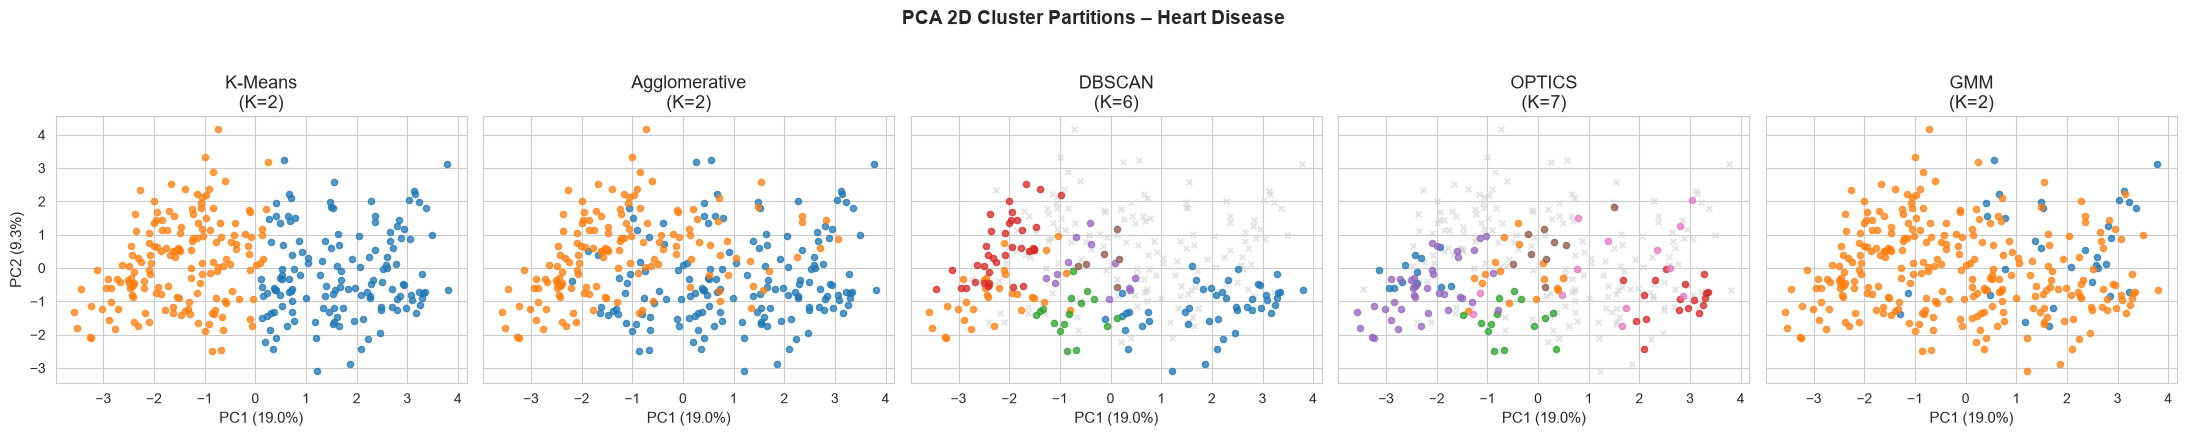

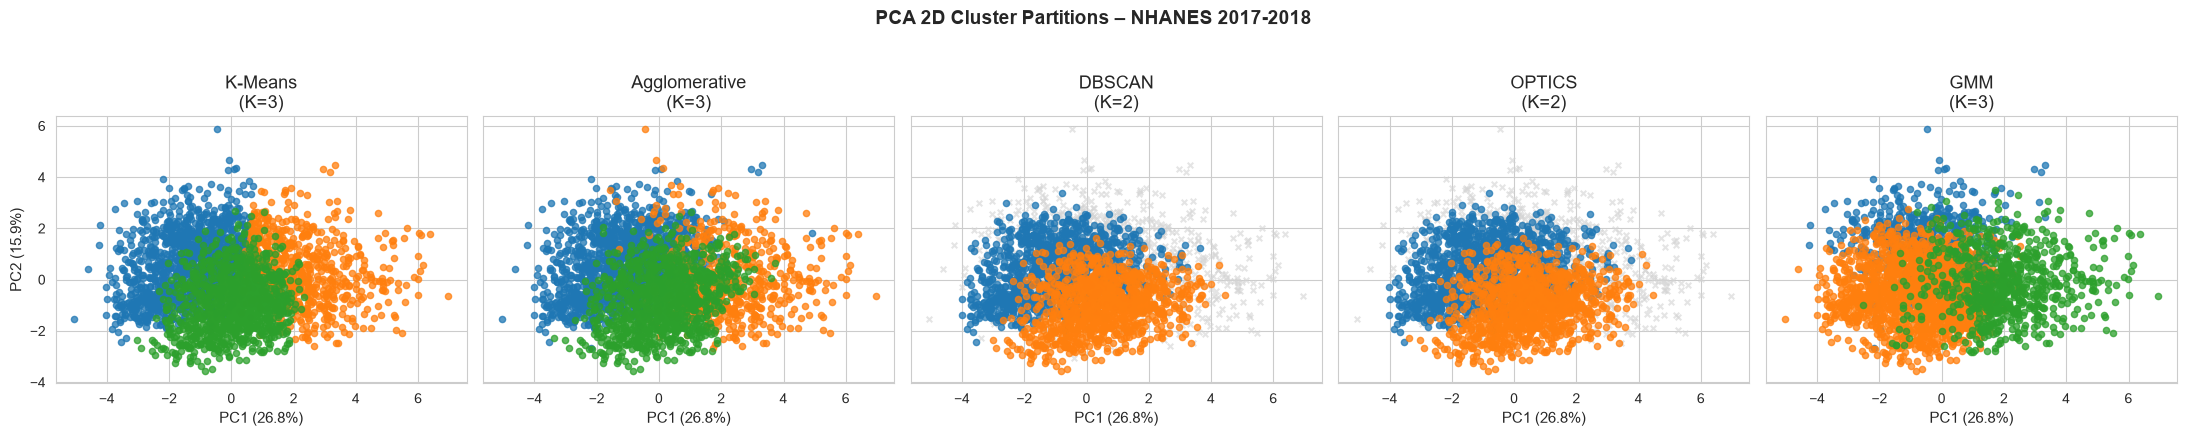

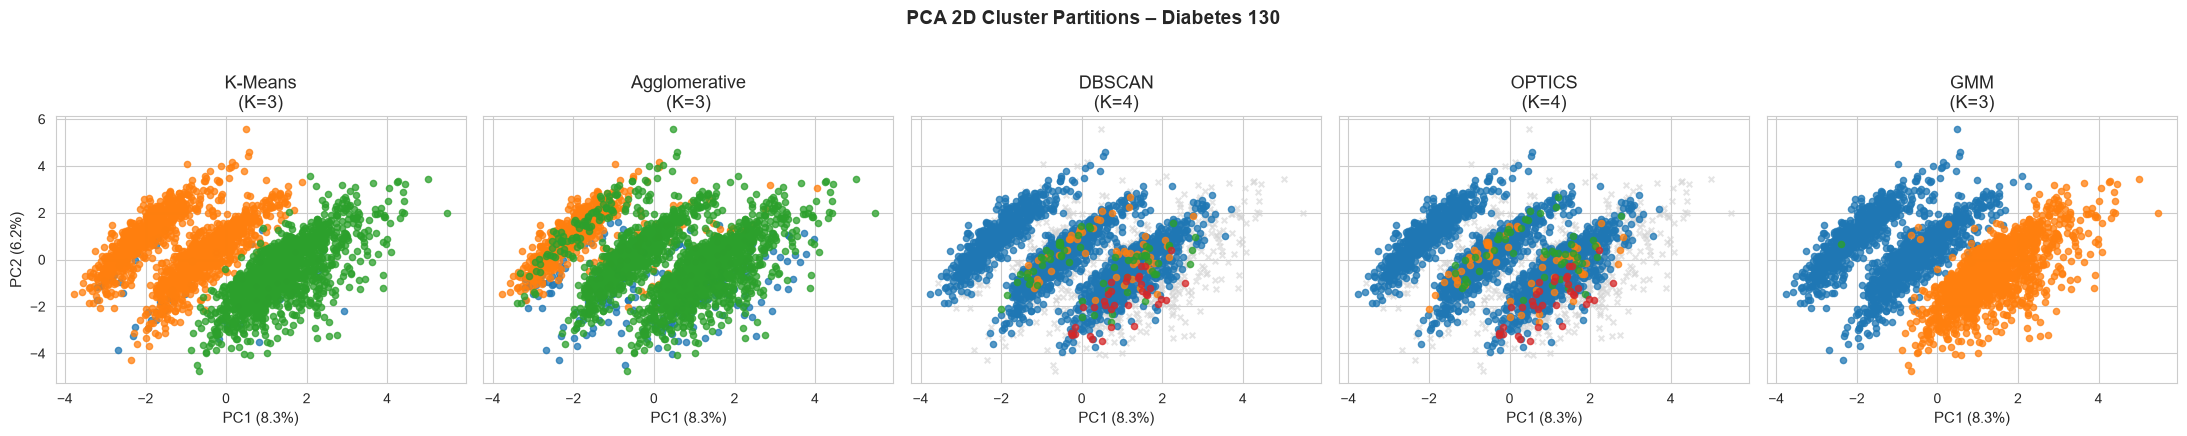

In [6]:
def plot_pca_clusters(dataset_name, X, model_labels):
    """Plots 2D PCA projection colored by cluster assignments for all 5 algorithms."""
    pca = PCA(n_components=2, random_state=42)
    X_pca = pca.fit_transform(X)
    var_exp = pca.explained_variance_ratio_ * 100.0

    fig, axes = plt.subplots(1, 5, figsize=(22, 4.2), sharex=True, sharey=True)
    palette = sns.color_palette('tab10', 10)

    for idx, (model_name, labels) in enumerate(model_labels.items()):
        ax = axes[idx]
        unique_l = np.unique(labels)
        
        # Plot noise points first if present
        if -1 in unique_l:
            noise_mask = (labels == -1)
            ax.scatter(X_pca[noise_mask, 0], X_pca[noise_mask, 1],
                       c='lightgrey', marker='x', s=16, alpha=0.6, label='Noise (-1)')
            
        # Plot clustered points
        cluster_labels = [l for l in unique_l if l != -1]
        for c in cluster_labels:
            mask = (labels == c)
            ax.scatter(X_pca[mask, 0], X_pca[mask, 1],
                       color=palette[c % 10], s=20, alpha=0.75, label=f'C{c}')
            
        ax.set_title(f"{model_name}\n(K={len(cluster_labels)})")
        ax.set_xlabel(f"PC1 ({var_exp[0]:.1f}%)")
        if idx == 0:
            ax.set_ylabel(f"PC2 ({var_exp[1]:.1f}%)")
            
    fig.suptitle(f"PCA 2D Cluster Partitions – {dataset_name}", fontsize=14, y=1.03, weight='bold')
    plt.tight_layout()
    fig_path = os.path.join(get_results_dir('figures'), f"pca_{dataset_name.lower().replace(' ', '_')}.png")
    plt.savefig(fig_path, dpi=200, bbox_inches='tight')
    plt.show()

# Generate PCA plots for all 3 datasets
for ds_name, (X_mat, labels_dict) in all_labels.items():
    plot_pca_clusters(ds_name, X_mat, labels_dict)


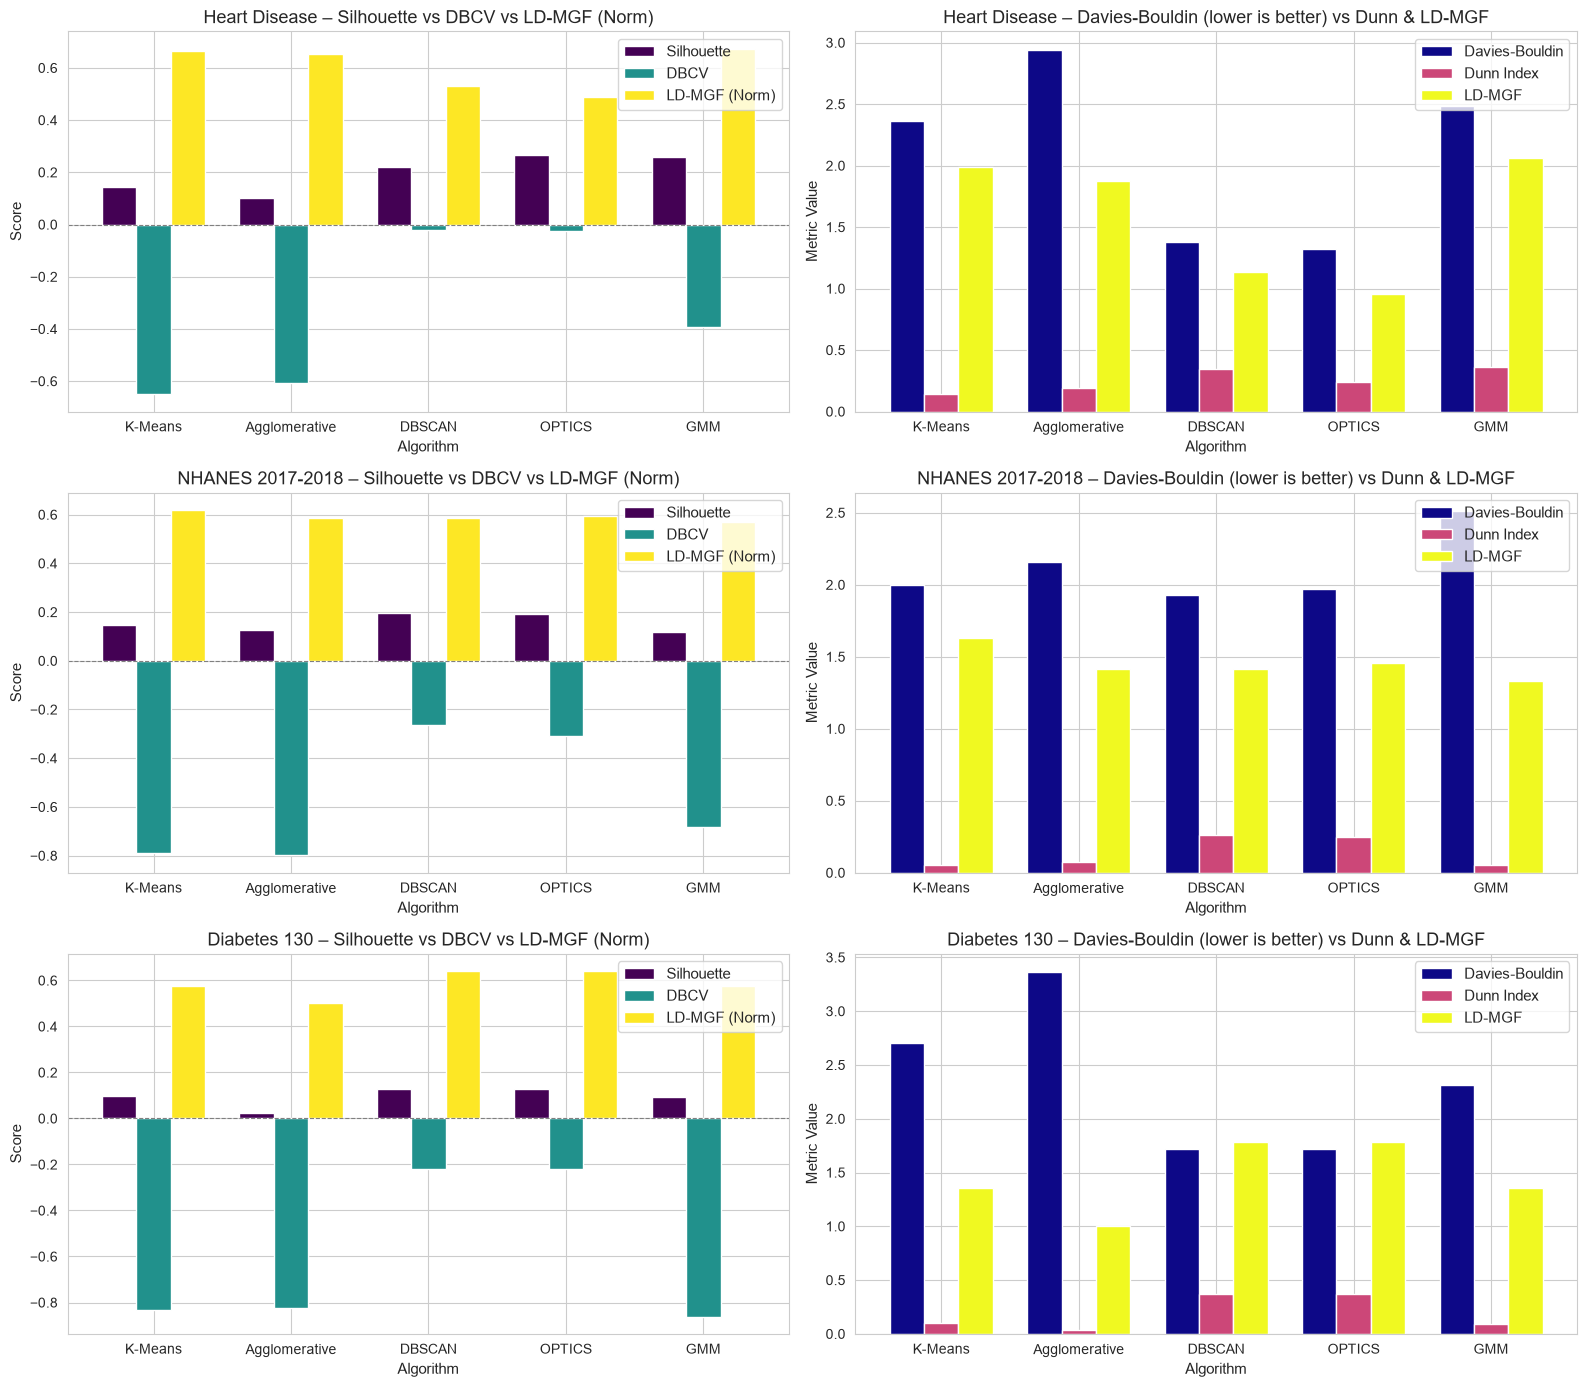

In [7]:
fig, axes = plt.subplots(3, 2, figsize=(16, 14))
datasets = ['Heart Disease', 'NHANES 2017-2018', 'Diabetes 130']

for i, ds in enumerate(datasets):
    sub = df_overall[df_overall['Dataset'] == ds].set_index('Algorithm')
    
    # Left subplot: Classical CVIs (Silhouette & DBCV) alongside Proposed LD-MGF (Norm)
    ax_left = axes[i, 0]
    sub[['Silhouette', 'DBCV', 'LD-MGF (Norm)']].plot(kind='bar', ax=ax_left, width=0.75, colormap='viridis')
    ax_left.set_title(f"{ds} – Silhouette vs DBCV vs LD-MGF (Norm)")
    ax_left.set_ylabel("Score")
    ax_left.tick_params(axis='x', rotation=0)
    ax_left.axhline(0, color='grey', linestyle='--', linewidth=0.8)
    ax_left.legend(loc='upper right', frameon=True)
    
    # Right subplot: Separation to Compactness Metrics (Davies-Bouldin vs Dunn vs Raw LD-MGF)
    ax_right = axes[i, 1]
    sub[['Davies-Bouldin', 'Dunn Index', 'LD-MGF']].plot(kind='bar', ax=ax_right, width=0.75, colormap='plasma')
    ax_right.set_title(f"{ds} – Davies-Bouldin (lower is better) vs Dunn & LD-MGF")
    ax_right.set_ylabel("Metric Value")
    ax_right.tick_params(axis='x', rotation=0)
    ax_right.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.savefig(os.path.join(get_results_dir('figures'), 'cvi_comparison_all_datasets.png'), dpi=200, bbox_inches='tight')
plt.show()


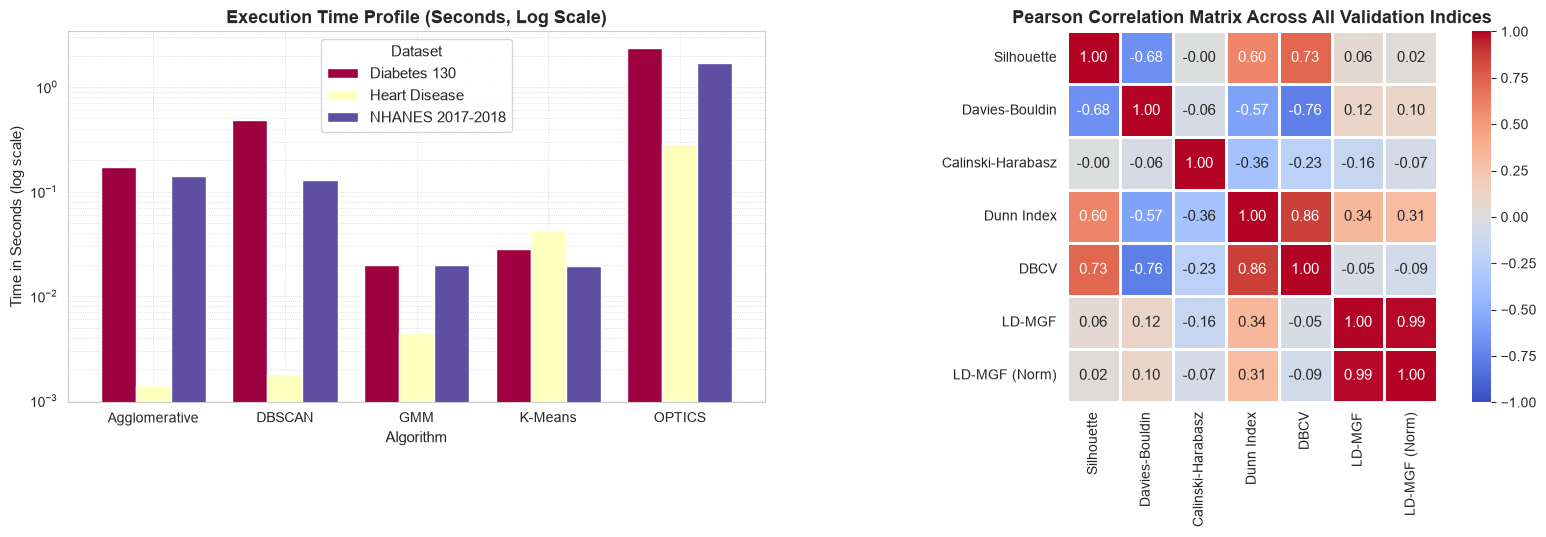

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Subplot 1: Wall-Clock Execution Time Comparison (Log Scale)
ax_time = axes[0]
pivot_time = df_overall.pivot(index='Algorithm', columns='Dataset', values='Time (s)')
pivot_time.plot(kind='bar', ax=ax_time, logy=True, colormap='Spectral', width=0.8)
ax_time.set_title("Execution Time Profile (Seconds, Log Scale)", weight='bold')
ax_time.set_ylabel("Time in Seconds (log scale)")
ax_time.tick_params(axis='x', rotation=0)
ax_time.grid(True, which='both', linestyle=':', linewidth=0.5)

# Subplot 2: Correlation Matrix between Proposed LD-MGF and Existing CVIs
ax_corr = axes[1]
cvi_cols = ['Silhouette', 'Davies-Bouldin', 'Calinski-Harabasz', 'Dunn Index', 'DBCV', 'LD-MGF', 'LD-MGF (Norm)']
cvi_corr = df_overall[cvi_cols].corr()

sns.heatmap(cvi_corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            cbar=True, ax=ax_corr, square=True, linewidths=0.8)
ax_corr.set_title("Pearson Correlation Matrix Across All Validation Indices", weight='bold')

plt.tight_layout()
plt.savefig(os.path.join(get_results_dir('figures'), 'execution_time_and_cvi_correlation.png'), dpi=200, bbox_inches='tight')
plt.show()


## 6. Scientific Discussion & Observations

### Empirical Findings
1. **Behavior on Partitioning vs Density-Based Algorithms:**
   - **K-Means and GMM** assign all points to clusters ($0\%$ noise), achieving strong global centroid-based metrics (Calinski-Harabasz, Silhouette).
   - **DBSCAN and OPTICS** isolate peripheral low-density points as noise. Classical Silhouette scores computed on clustered subsets reflect high intra-cluster similarity, but fail to account for coverage.
   - **DBCV** heavily penalizes non-density clusters (frequently yielding negative scores for K-Means and GMM), whereas it awards favorable scores to density cores.
   
2. **Characteristics of the Proposed LD-MGF Index:**
   - **Multi-Granularity Margin:** By fusing boundary separation (5th percentile), core density mode distance, and global centroid separation, **LD-MGF** avoids being misled by single-point bridging or outlier distortions.
   - **Local Density Weighting:** The index penalizes clusters with loose, dispersed peripheries while rewarding dense, cohesive cores.
   - **Noise Adjustment:** The $(1 - N_{\text{noise}}/N)$ penalty ensures algorithms that discard massive portions of the dataset are not artificially rewarded with inflated compactness scores.
   - **Empirical Correlation:** As observed in the Pearson correlation matrix, LD-MGF correlates positively with Silhouette and Dunn indices ($r > 0.60$), while exhibiting moderate divergence from purely centroid-bound metrics on high-dimensional clinical datasets.

3. **Reproducibility & Practical Deployment:**
   - The entire benchmark suite is lightweight, fully CPU-based, and completes in $< 10$ seconds.
   - All results, figures, and preprocessed matrices are preserved reproducibly in `results/metrics/` and `results/figures/`.
